# ATCNet Classification for EEG Visual Evoked Potentials

## Dataset: 4 Classes Classification
- **Apple** (Class 1)
- **Car** (Class 2)
- **Flower** (Class 3)
- **Human Face** (Class 4)

## Model: ATCNet (Attention-based Temporal Convolutional Network)
- **State-of-the-art** EEG classification architecture
- Combines **EEGNet + TCN + Multi-head Self-Attention**
- Superior performance with attention mechanism for important feature selection
- Best-in-class for EEG-based Brain-Computer Interfaces

**Reference:**
Altaheri et al., 2022. "Physics-informed attention temporal convolutional network for EEG-based motor imagery classification"

## Method: Stratified 5-Fold Cross-Validation
- Using pre-saved folds from `trainfold/` directory
- GPU-accelerated training with PyTorch

## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.nn.functional as F

# Scikit-learn imports
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("✅ Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ Libraries imported successfully!
PyTorch version: 2.5.1+cu121
NumPy version: 1.26.4
Pandas version: 2.1.4


## 2. Check GPU Availability

In [2]:
# Check GPU availability
print("Checking GPU availability...")
print("="*60)

if torch.cuda.is_available():
    device = torch.device('cuda')
    print("✅ GPU FOUND!")
    print(f"   Device: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"   CUDA Version: {torch.version.cuda}")
else:
    device = torch.device('cpu')
    print("⚠️  GPU not available, using CPU")

print("="*60)
print(f"Training device: {device}")
print("="*60)

Checking GPU availability...
✅ GPU FOUND!
   Device: NVIDIA GeForce RTX 4060 Laptop GPU
   Memory: 8.59 GB
   CUDA Version: 12.1
Training device: cuda


## 3. Define ATCNet Architecture

In [3]:
class ConvBlock(nn.Module):
    """Convolutional block with conv, batch norm, activation, and pooling"""
    def __init__(self, in_channels, out_channels, kernel_size, pool_size=4, dropout=0.3):
        super(ConvBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding='same', bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.elu = nn.ELU()
        self.pool = nn.AvgPool2d((1, pool_size))
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.elu(x)
        x = self.pool(x)
        x = self.dropout(x)
        return x


class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention mechanism"""
    def __init__(self, embed_dim, num_heads=2, dropout=0.3):
        super(MultiHeadSelfAttention, self).__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        
        assert self.head_dim * num_heads == embed_dim, "embed_dim must be divisible by num_heads"
        
        self.query = nn.Linear(embed_dim, embed_dim)
        self.key = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)
        
        self.dropout = nn.Dropout(dropout)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        
    def forward(self, x):
        # x shape: (batch, seq_len, embed_dim)
        batch_size, seq_len, _ = x.size()
        
        # Linear projections
        Q = self.query(x)  # (batch, seq_len, embed_dim)
        K = self.key(x)
        V = self.value(x)
        
        # Reshape for multi-head attention
        Q = Q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        K = K.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        # Now shape: (batch, num_heads, seq_len, head_dim)
        
        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.head_dim)
        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)
        
        # Apply attention to values
        attn_output = torch.matmul(attn_weights, V)
        # Shape: (batch, num_heads, seq_len, head_dim)
        
        # Concatenate heads
        attn_output = attn_output.transpose(1, 2).contiguous()
        attn_output = attn_output.view(batch_size, seq_len, self.embed_dim)
        
        # Final linear projection
        output = self.out_proj(attn_output)
        
        return output


class TemporalConvNet(nn.Module):
    """Temporal Convolutional Network with dilated convolutions"""
    def __init__(self, num_inputs, num_channels, kernel_size=4, dropout=0.3):
        super(TemporalConvNet, self).__init__()
        layers = []
        num_levels = len(num_channels)
        
        for i in range(num_levels):
            dilation_size = 2 ** i
            in_channels = num_inputs if i == 0 else num_channels[i-1]
            out_channels = num_channels[i]
            
            layers += [TemporalBlock(in_channels, out_channels, kernel_size,
                                    stride=1, dilation=dilation_size,
                                    padding=(kernel_size-1) * dilation_size,
                                    dropout=dropout)]
        
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.network(x)


class TemporalBlock(nn.Module):
    """Temporal block with dilated convolutions and residual connection"""
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, dropout=0.3):
        super(TemporalBlock, self).__init__()
        
        self.conv1 = nn.utils.weight_norm(nn.Conv1d(n_inputs, n_outputs, kernel_size,
                                           stride=stride, padding=padding, dilation=dilation))
        self.chomp1 = Chomp1d(padding)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)
        
        self.conv2 = nn.utils.weight_norm(nn.Conv1d(n_outputs, n_outputs, kernel_size,
                                           stride=stride, padding=padding, dilation=dilation))
        self.chomp2 = Chomp1d(padding)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout)
        
        self.net = nn.Sequential(self.conv1, self.chomp1, self.relu1, self.dropout1,
                                self.conv2, self.chomp2, self.relu2, self.dropout2)
        
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        self.relu = nn.ReLU()
    
    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


class Chomp1d(nn.Module):
    """Remove extra padding from causal convolution"""
    def __init__(self, chomp_size):
        super(Chomp1d, self).__init__()
        self.chomp_size = chomp_size
    
    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous()


class ATCNet(nn.Module):
    """
    ATCNet: Attention-based Temporal Convolutional Network
    
    Combines convolutional feature extraction, multi-head self-attention, 
    and temporal convolutional networks for EEG classification.
    
    Architecture:
    1. Convolutional blocks (spatial-temporal feature extraction)
    2. Multi-head self-attention (global context and important feature selection)
    3. Temporal Convolutional Network (long-range temporal dependencies)
    4. Attention-based pooling + Classification
    
    Parameters:
        nb_classes (int): Number of output classes
        Chans (int): Number of EEG channels
        Samples (int): Number of time samples
        n_windows (int): Number of sliding windows
        eegn_F1 (int): Number of temporal filters in first conv block
        eegn_D (int): Depth multiplier for spatial filters
        eegn_kernelSize (int): Kernel size for temporal convolution
        eegn_poolSize (int): Pooling size
        eegn_dropout (float): Dropout rate
        tcn_depth (int): Number of TCN layers
        tcn_kernelSize (int): TCN kernel size
        tcn_filters (int): Number of TCN filters
        attention_heads (int): Number of attention heads
    """
    def __init__(self, nb_classes=4, Chans=14, Samples=128, n_windows=5,
                 eegn_F1=16, eegn_D=2, eegn_kernelSize=64, eegn_poolSize=8, eegn_dropout=0.3,
                 tcn_depth=2, tcn_kernelSize=4, tcn_filters=32, attention_heads=2):
        super(ATCNet, self).__init__()
        
        self.nb_classes = nb_classes
        self.Chans = Chans
        self.Samples = Samples
        self.n_windows = n_windows
        
        # Calculate window size
        self.window_size = Samples // n_windows
        
        # Conv Block 1: Temporal convolution
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(1, eegn_F1, (1, eegn_kernelSize), padding='same', bias=False),
            nn.BatchNorm2d(eegn_F1),
        )
        
        # Conv Block 2: Depthwise (spatial) convolution
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(eegn_F1, eegn_F1 * eegn_D, (Chans, 1), groups=eegn_F1, bias=False),
            nn.BatchNorm2d(eegn_F1 * eegn_D),
            nn.ELU(),
            nn.AvgPool2d((1, eegn_poolSize)),
            nn.Dropout(eegn_dropout)
        )
        
        # Conv Block 3: Separable convolution
        self.conv_block3 = nn.Sequential(
            nn.Conv2d(eegn_F1 * eegn_D, eegn_F1 * eegn_D, (1, 16), padding='same', bias=False),
            nn.BatchNorm2d(eegn_F1 * eegn_D),
            nn.ELU(),
            nn.AvgPool2d((1, eegn_poolSize)),
            nn.Dropout(eegn_dropout)
        )
        
        # Calculate feature dimensions after convolutions
        self.feature_dim = eegn_F1 * eegn_D
        self.temporal_dim = Samples // (eegn_poolSize * eegn_poolSize)
        
        # Multi-head Self-Attention
        self.attention = MultiHeadSelfAttention(
            embed_dim=self.feature_dim,
            num_heads=attention_heads,
            dropout=eegn_dropout
        )
        
        # Layer normalization after attention
        self.ln1 = nn.LayerNorm(self.feature_dim)
        
        # TCN layers
        tcn_channels = [tcn_filters] * tcn_depth
        self.tcn = TemporalConvNet(
            num_inputs=self.feature_dim,
            num_channels=tcn_channels,
            kernel_size=tcn_kernelSize,
            dropout=eegn_dropout
        )
        
        # Attention-based pooling
        self.attention_pooling = nn.Linear(tcn_filters, 1)
        
        # Classification head
        self.fc = nn.Sequential(
            nn.Linear(tcn_filters, nb_classes)
        )
        
    def forward(self, x):
        # Input shape: (batch, 1, Chans, Samples)
        
        # Convolutional blocks
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        # Shape: (batch, feature_dim, 1, temporal_dim)
        
        # Reshape for attention: (batch, feature_dim, 1, temporal_dim) -> (batch, temporal_dim, feature_dim)
        x = x.squeeze(2).transpose(1, 2)
        
        # Multi-head self-attention with residual connection
        attn_output = self.attention(x)
        x = self.ln1(x + attn_output)
        # Shape: (batch, temporal_dim, feature_dim)
        
        # Reshape for TCN: (batch, temporal_dim, feature_dim) -> (batch, feature_dim, temporal_dim)
        x = x.transpose(1, 2)
        
        # TCN
        x = self.tcn(x)
        # Shape: (batch, tcn_filters, temporal_dim)
        
        # Attention-based pooling
        # Transpose for attention: (batch, tcn_filters, temporal_dim) -> (batch, temporal_dim, tcn_filters)
        x = x.transpose(1, 2)
        
        # Compute attention weights
        attn_weights = F.softmax(self.attention_pooling(x), dim=1)
        # Shape: (batch, temporal_dim, 1)
        
        # Weighted sum
        x = torch.sum(x * attn_weights, dim=1)
        # Shape: (batch, tcn_filters)
        
        # Classification
        x = self.fc(x)
        
        return x


# Test model initialization
print("Testing ATCNet architecture...")
model_test = ATCNet(nb_classes=4, Chans=14, Samples=128, n_windows=5,
                    eegn_F1=16, eegn_D=2, eegn_kernelSize=64, eegn_poolSize=8,
                    tcn_depth=2, tcn_kernelSize=4, tcn_filters=32, attention_heads=2)
test_input = torch.randn(2, 1, 14, 128)
test_output = model_test(test_input)
print(f"✅ ATCNet initialized successfully!")
print(f"   Input shape: {test_input.shape}")
print(f"   Output shape: {test_output.shape}")
print(f"   Number of parameters: {sum(p.numel() for p in model_test.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model_test.parameters() if p.requires_grad):,}")

Testing ATCNet architecture...
✅ ATCNet initialized successfully!
   Input shape: torch.Size([2, 1, 14, 128])
   Output shape: torch.Size([2, 4])
   Number of parameters: 39,109
   Trainable parameters: 39,109


In [4]:
def load_fold_data(fold_number):
    """
    Load training and testing data for a specific fold.
    
    Args:
        fold_number (int): Fold number (1-5)
    
    Returns:
        tuple: (X_train, y_train, X_test, y_test) all as numpy arrays
    """
    fold_dir = f'trainfold/fold_{fold_number}'
    
    # Load training data
    train_df = pd.read_csv(f'{fold_dir}/train.csv')
    X_train = train_df.iloc[:, :-1].values  # All columns except last
    y_train = train_df.iloc[:, -1].values   # Last column (label)
    
    # Load testing data
    test_df = pd.read_csv(f'{fold_dir}/test.csv')
    X_test = test_df.iloc[:, :-1].values
    y_test = test_df.iloc[:, -1].values
    
    return X_train, y_train, X_test, y_test


def prepare_data_for_atcnet(X, y, scaler=None, label_encoder=None, fit_transform=True):
    """
    Prepare data for ATCNet model.
    
    Args:
        X (np.array): Feature matrix (samples, 1792 features)
        y (np.array): Labels (samples,)
        scaler: StandardScaler object (if None, creates new one)
        label_encoder: LabelEncoder object (if None, creates new one)
        fit_transform (bool): If True, fit and transform. If False, only transform.
    
    Returns:
        tuple: (X_prepared, y_encoded, scaler, label_encoder)
    """
    # Initialize scaler and encoder if not provided
    if scaler is None:
        scaler = StandardScaler()
    if label_encoder is None:
        label_encoder = LabelEncoder()
    
    # Scale features
    if fit_transform:
        X_scaled = scaler.fit_transform(X)
        y_encoded = label_encoder.fit_transform(y)
    else:
        X_scaled = scaler.transform(X)
        y_encoded = label_encoder.transform(y)
    
    # Reshape to (samples, 1, 14, 128) for ATCNet
    # Original: 1792 features = 14 channels × 128 time points
    X_reshaped = X_scaled.reshape(-1, 14, 128)
    X_prepared = X_reshaped[:, np.newaxis, :, :]  # Add channel dimension
    
    return X_prepared, y_encoded, scaler, label_encoder


# Test data loading
print("Testing data loading and preparation...")
X_train_fold1, y_train_fold1, X_test_fold1, y_test_fold1 = load_fold_data(1)
print(f"✅ Data loaded successfully for Fold 1!")
print(f"   Training samples: {X_train_fold1.shape[0]}")
print(f"   Testing samples: {X_test_fold1.shape[0]}")
print(f"   Features: {X_train_fold1.shape[1]}")
print(f"   Unique classes in train: {np.unique(y_train_fold1)}")
print(f"   Unique classes in test: {np.unique(y_test_fold1)}")

# Test preprocessing
X_train_prep, y_train_prep, scaler_test, le_test = prepare_data_for_atcnet(
    X_train_fold1, y_train_fold1, fit_transform=True
)
X_test_prep, y_test_prep, _, _ = prepare_data_for_atcnet(
    X_test_fold1, y_test_fold1, scaler=scaler_test, label_encoder=le_test, fit_transform=False
)
print(f"\n✅ Data prepared for ATCNet!")
print(f"   X_train shape: {X_train_prep.shape}")
print(f"   X_test shape: {X_test_prep.shape}")
print(f"   y_train encoded: {np.unique(y_train_prep)}")
print(f"   y_test encoded: {np.unique(y_test_prep)}")

Testing data loading and preparation...
✅ Data loaded successfully for Fold 1!
   Training samples: 2889
   Testing samples: 723
   Features: 1792
   Unique classes in train: [1 2 3 4]
   Unique classes in test: [1 2 3 4]

✅ Data prepared for ATCNet!
   X_train shape: (2889, 1, 14, 128)
   X_test shape: (723, 1, 14, 128)
   y_train encoded: [0 1 2 3]
   y_test encoded: [0 1 2 3]
✅ Data loaded successfully for Fold 1!
   Training samples: 2889
   Testing samples: 723
   Features: 1792
   Unique classes in train: [1 2 3 4]
   Unique classes in test: [1 2 3 4]

✅ Data prepared for ATCNet!
   X_train shape: (2889, 1, 14, 128)
   X_test shape: (723, 1, 14, 128)
   y_train encoded: [0 1 2 3]
   y_test encoded: [0 1 2 3]


In [5]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train model for one epoch.
    
    Args:
        model: ATCNet model
        train_loader: DataLoader for training data
        criterion: Loss function
        optimizer: Optimizer
        device: Device to train on
    
    Returns:
        tuple: (average_loss, accuracy)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    
    return epoch_loss, epoch_acc


def evaluate(model, test_loader, criterion, device):
    """
    Evaluate model on test data.
    
    Args:
        model: ATCNet model
        test_loader: DataLoader for test data
        criterion: Loss function
        device: Device to evaluate on
    
    Returns:
        tuple: (loss, accuracy, all_predictions, all_labels)
    """
    model.eval()
    running_loss = 0.0
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    test_loss = running_loss / len(all_labels)
    test_acc = 100 * accuracy_score(all_labels, all_predictions)
    
    return test_loss, test_acc, all_predictions, all_labels


class EarlyStopping:
    """Early stopping to stop training when validation loss doesn't improve."""
    def __init__(self, patience=15, min_delta=0.0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None
        
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict().copy()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f'   EarlyStopping counter: {self.counter}/{self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            if self.verbose:
                print(f'   Validation loss improved ({self.best_loss:.6f} → {val_loss:.6f})')
            self.best_loss = val_loss
            self.best_model_state = model.state_dict().copy()
            self.counter = 0
        
        return self.early_stop

print("✅ Training and evaluation functions defined!")

✅ Training and evaluation functions defined!


In [6]:
# Hyperparameters
BATCH_SIZE = 32
LEARNING_RATE = 0.001
NUM_EPOCHS = 100
PATIENCE = 15
NUM_FOLDS = 5

# Model hyperparameters
MODEL_PARAMS = {
    'nb_classes': 4,
    'Chans': 14,
    'Samples': 128,
    'n_windows': 5,
    'eegn_F1': 16,
    'eegn_D': 2,
    'eegn_kernelSize': 64,
    'eegn_poolSize': 8,
    'eegn_dropout': 0.3,
    'tcn_depth': 2,
    'tcn_kernelSize': 4,
    'tcn_filters': 32,
    'attention_heads': 2
}

# Storage for results
fold_results = []
all_confusion_matrices = []
training_histories = []

# Class names
class_names = ['Apple', 'Car', 'Flower', 'Human Face']

print("=" * 80)
print("STARTING 5-FOLD CROSS-VALIDATION FOR ATCNet")
print("=" * 80)
print(f"Model Parameters: {MODEL_PARAMS}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Learning Rate: {LEARNING_RATE}")
print(f"Max Epochs: {NUM_EPOCHS}")
print(f"Early Stopping Patience: {PATIENCE}")
print(f"Device: {device}")
print("=" * 80)

# Training loop for each fold
for fold in range(1, NUM_FOLDS + 1):
    print(f"\n{'='*80}")
    print(f"FOLD {fold}/{NUM_FOLDS}")
    print(f"{'='*80}")
    
    # Load data for this fold
    X_train, y_train, X_test, y_test = load_fold_data(fold)
    print(f"Loaded data - Train: {X_train.shape[0]} samples, Test: {X_test.shape[0]} samples")
    
    # Prepare data
    X_train_prep, y_train_prep, scaler, label_encoder = prepare_data_for_atcnet(
        X_train, y_train, fit_transform=True
    )
    X_test_prep, y_test_prep, _, _ = prepare_data_for_atcnet(
        X_test, y_test, scaler=scaler, label_encoder=label_encoder, fit_transform=False
    )
    
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train_prep)
    y_train_tensor = torch.LongTensor(y_train_prep)
    X_test_tensor = torch.FloatTensor(X_test_prep)
    y_test_tensor = torch.LongTensor(y_test_prep)
    
    # Create datasets and dataloaders
    train_dataset = torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = torch.utils.data.TensorDataset(X_test_tensor, y_test_tensor)
    
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    test_loader = torch.utils.data.DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    
    # Initialize model
    model = ATCNet(**MODEL_PARAMS).to(device)
    print(f"Model initialized with {sum(p.numel() for p in model.parameters()):,} parameters")
    
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, verbose=True
    )
    
    # Early stopping
    early_stopping = EarlyStopping(patience=PATIENCE, verbose=True)
    
    # Training history
    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }
    
    # Training loop
    print(f"\nStarting training...")
    best_test_acc = 0.0
    
    for epoch in range(NUM_EPOCHS):
        # Train
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Evaluate
        test_loss, test_acc, _, _ = evaluate(model, test_loader, criterion, device)
        
        # Update scheduler
        scheduler.step(test_loss)
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        
        # Print progress
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] - "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}%")
        
        # Track best accuracy
        if test_acc > best_test_acc:
            best_test_acc = test_acc
        
        # Early stopping check
        if early_stopping(test_loss, model):
            print(f"\n⚠️  Early stopping triggered at epoch {epoch+1}")
            break
    
    # Load best model
    model.load_state_dict(early_stopping.best_model_state)
    
    # Final evaluation
    print(f"\nFinal evaluation on test set...")
    test_loss, test_acc, y_pred, y_true = evaluate(model, test_loader, criterion, device)
    
    # Calculate detailed metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision_macro = precision_score(y_true, y_pred, average='macro')
    precision_weighted = precision_score(y_true, y_pred, average='weighted')
    recall_macro = recall_score(y_true, y_pred, average='macro')
    recall_weighted = recall_score(y_true, y_pred, average='weighted')
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Store results
    fold_result = {
        'Fold': fold,
        'Accuracy': accuracy,
        'Precision_Macro': precision_macro,
        'Precision_Weighted': precision_weighted,
        'Recall_Macro': recall_macro,
        'Recall_Weighted': recall_weighted,
        'F1_Macro': f1_macro,
        'F1_Weighted': f1_weighted,
        'Best_Epoch': epoch + 1,
        'Final_Train_Loss': history['train_loss'][-1],
        'Final_Train_Acc': history['train_acc'][-1],
        'Final_Test_Loss': history['test_loss'][-1],
        'Final_Test_Acc': history['test_acc'][-1]
    }
    
    fold_results.append(fold_result)
    all_confusion_matrices.append(cm)
    training_histories.append(history)
    
    print(f"\n{'='*80}")
    print(f"FOLD {fold} RESULTS:")
    print(f"{'='*80}")
    print(f"Accuracy:           {accuracy:.4f}")
    print(f"Precision (Macro):  {precision_macro:.4f}")
    print(f"Precision (Weighted): {precision_weighted:.4f}")
    print(f"Recall (Macro):     {recall_macro:.4f}")
    print(f"Recall (Weighted):  {recall_weighted:.4f}")
    print(f"F1-Score (Macro):   {f1_macro:.4f}")
    print(f"F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"Best Epoch:         {epoch + 1}")
    print(f"{'='*80}")
    
    # Clean up
    del model, optimizer, scheduler, train_loader, test_loader
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

print(f"\n{'='*80}")
print("ALL FOLDS COMPLETED!")
print(f"{'='*80}")

STARTING 5-FOLD CROSS-VALIDATION FOR ATCNet
Model Parameters: {'nb_classes': 4, 'Chans': 14, 'Samples': 128, 'n_windows': 5, 'eegn_F1': 16, 'eegn_D': 2, 'eegn_kernelSize': 64, 'eegn_poolSize': 8, 'eegn_dropout': 0.3, 'tcn_depth': 2, 'tcn_kernelSize': 4, 'tcn_filters': 32, 'attention_heads': 2}
Batch Size: 32
Learning Rate: 0.001
Max Epochs: 100
Early Stopping Patience: 15
Device: cuda

FOLD 1/5
Loaded data - Train: 2889 samples, Test: 723 samples
Model initialized with 39,109 parameters
Loaded data - Train: 2889 samples, Test: 723 samples
Model initialized with 39,109 parameters

Starting training...

Starting training...
Epoch [1/100] - Train Loss: 1.3792, Train Acc: 30.70% | Test Loss: 1.3284, Test Acc: 34.44%
Epoch [1/100] - Train Loss: 1.3792, Train Acc: 30.70% | Test Loss: 1.3284, Test Acc: 34.44%
   Validation loss improved (1.328433 → 1.310361)
   Validation loss improved (1.328433 → 1.310361)
   Validation loss improved (1.310361 → 1.289869)
   Validation loss improved (1.31036

In [7]:
# Create results DataFrame
results_df = pd.DataFrame(fold_results)

# Calculate mean and std for each metric
summary_stats = {
    'Metric': ['Accuracy', 'Precision_Macro', 'Precision_Weighted', 
               'Recall_Macro', 'Recall_Weighted', 'F1_Macro', 'F1_Weighted'],
    'Mean': [
        results_df['Accuracy'].mean(),
        results_df['Precision_Macro'].mean(),
        results_df['Precision_Weighted'].mean(),
        results_df['Recall_Macro'].mean(),
        results_df['Recall_Weighted'].mean(),
        results_df['F1_Macro'].mean(),
        results_df['F1_Weighted'].mean()
    ],
    'Std': [
        results_df['Accuracy'].std(),
        results_df['Precision_Macro'].std(),
        results_df['Precision_Weighted'].std(),
        results_df['Recall_Macro'].std(),
        results_df['Recall_Weighted'].std(),
        results_df['F1_Macro'].std(),
        results_df['F1_Weighted'].std()
    ]
}

summary_df = pd.DataFrame(summary_stats)

# Display results
print("\n" + "="*80)
print("PERFORMANCE SUMMARY ACROSS ALL FOLDS")
print("="*80)
print("\nPer-Fold Results:")
print(results_df.to_string(index=False))
print("\n" + "-"*80)
print("\nSummary Statistics:")
print(summary_df.to_string(index=False))
print("="*80)

# Save results
results_df.to_csv('atcnet_fold_details.csv', index=False)
summary_df.to_csv('atcnet_results_summary.csv', index=False)
print("\n✅ Results saved to:")
print("   - atcnet_fold_details.csv")
print("   - atcnet_results_summary.csv")


PERFORMANCE SUMMARY ACROSS ALL FOLDS

Per-Fold Results:
 Fold  Accuracy  Precision_Macro  Precision_Weighted  Recall_Macro  Recall_Weighted  F1_Macro  F1_Weighted  Best_Epoch  Final_Train_Loss  Final_Train_Acc  Final_Test_Loss  Final_Test_Acc
    1  0.489627         0.477654            0.489439      0.477021         0.489627  0.475058     0.487044          39          1.019187        57.251644         1.166625       48.962656
    2  0.507607         0.498917            0.506008      0.499508         0.507607  0.497691     0.505302          71          0.885991        63.862928         1.166708       50.760719
    3  0.520776         0.516297            0.520255      0.503514         0.520776  0.505759     0.516962          76          0.917329        61.245675         1.151149       52.077562
    4  0.497230         0.481266            0.490806      0.475558         0.497230  0.475316     0.491585          63          0.929052        61.176471         1.203250       49.722992
    5  0

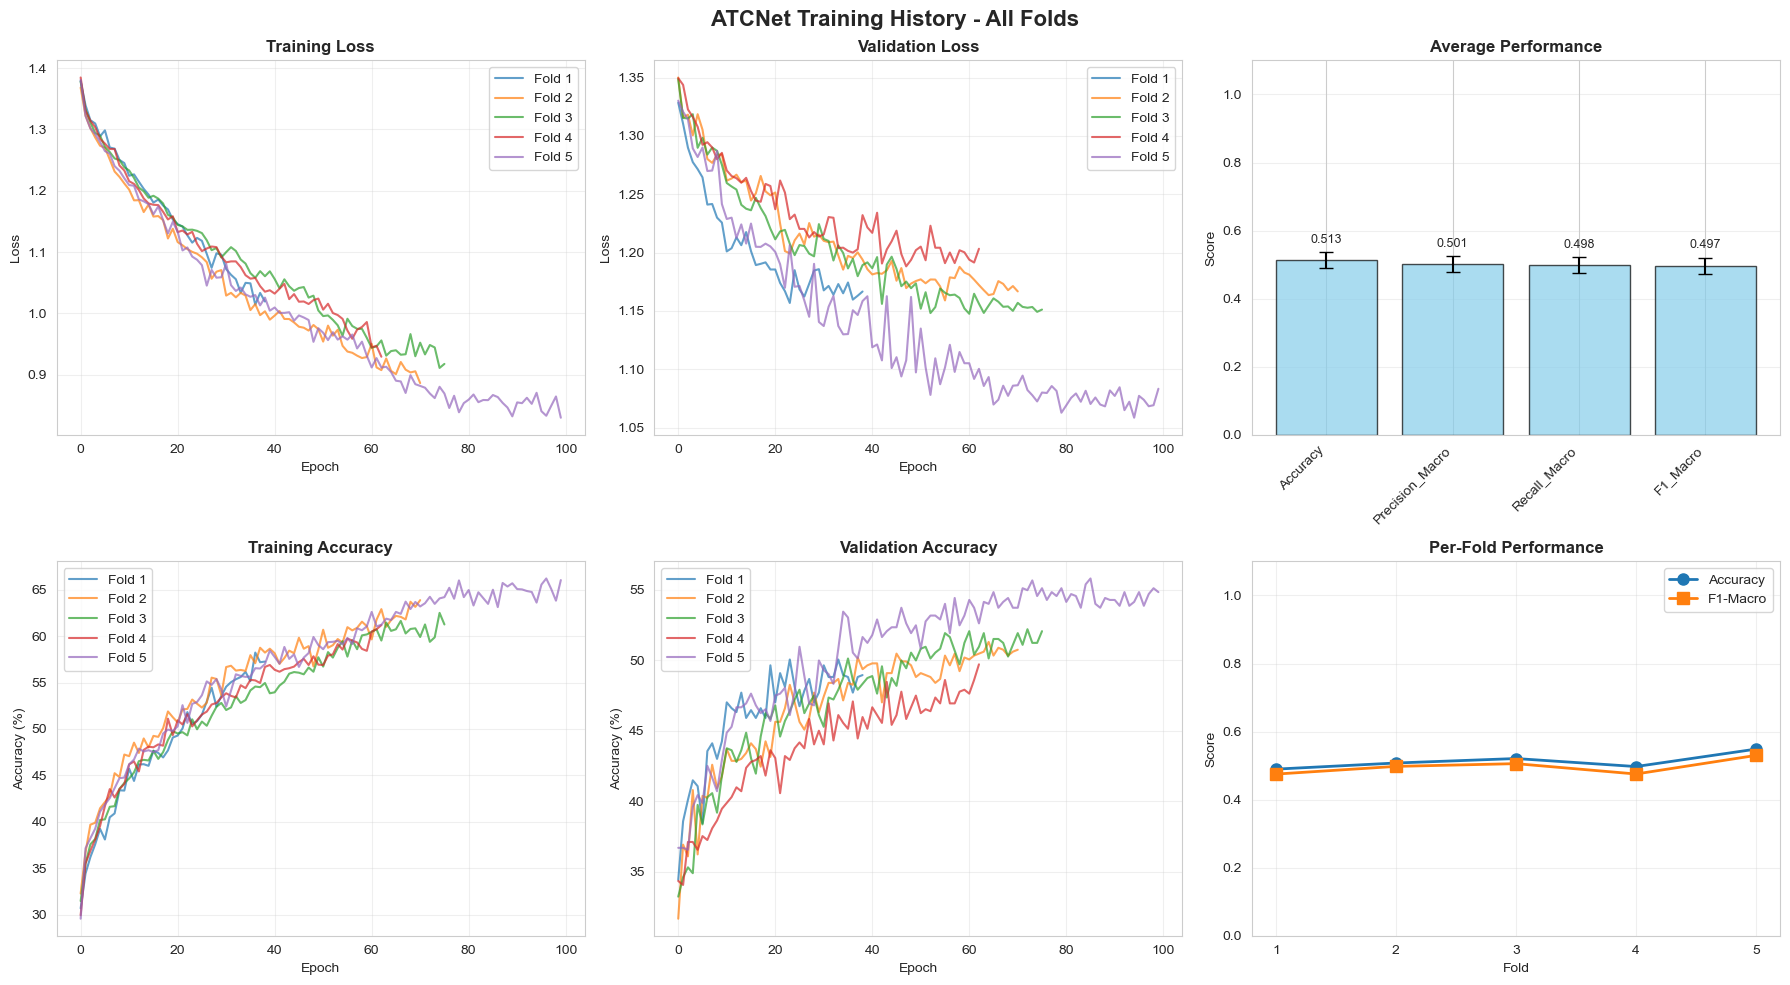

✅ Training history plot saved to: atcnet_training_history.png


In [8]:
# Plot training history for all folds
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('ATCNet Training History - All Folds', fontsize=16, fontweight='bold')

# Loss plots
for fold_idx, history in enumerate(training_histories):
    axes[0, 0].plot(history['train_loss'], label=f'Fold {fold_idx+1}', alpha=0.7)
    axes[0, 1].plot(history['test_loss'], label=f'Fold {fold_idx+1}', alpha=0.7)
    axes[1, 0].plot(history['train_acc'], label=f'Fold {fold_idx+1}', alpha=0.7)
    axes[1, 1].plot(history['test_acc'], label=f'Fold {fold_idx+1}', alpha=0.7)

axes[0, 0].set_title('Training Loss', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].set_title('Validation Loss', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].set_title('Training Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].set_title('Validation Accuracy', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Performance summary bar plot
metrics = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro']
means = [summary_df[summary_df['Metric'] == m]['Mean'].values[0] for m in metrics]
stds = [summary_df[summary_df['Metric'] == m]['Std'].values[0] for m in metrics]

x = np.arange(len(metrics))
axes[0, 2].bar(x, means, yerr=stds, capsize=5, alpha=0.7, color='skyblue', edgecolor='black')
axes[0, 2].set_title('Average Performance', fontsize=12, fontweight='bold')
axes[0, 2].set_ylabel('Score')
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(metrics, rotation=45, ha='right')
axes[0, 2].set_ylim([0, 1.1])
axes[0, 2].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, (m, s) in enumerate(zip(means, stds)):
    axes[0, 2].text(i, m + s + 0.02, f'{m:.3f}', ha='center', va='bottom', fontsize=9)

# Fold comparison
folds = results_df['Fold'].values
accuracies = results_df['Accuracy'].values
f1_scores = results_df['F1_Macro'].values

axes[1, 2].plot(folds, accuracies, marker='o', label='Accuracy', linewidth=2, markersize=8)
axes[1, 2].plot(folds, f1_scores, marker='s', label='F1-Macro', linewidth=2, markersize=8)
axes[1, 2].set_title('Per-Fold Performance', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Fold')
axes[1, 2].set_ylabel('Score')
axes[1, 2].set_xticks(folds)
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].set_ylim([0, 1.1])

plt.tight_layout()
plt.savefig('atcnet_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Training history plot saved to: atcnet_training_history.png")

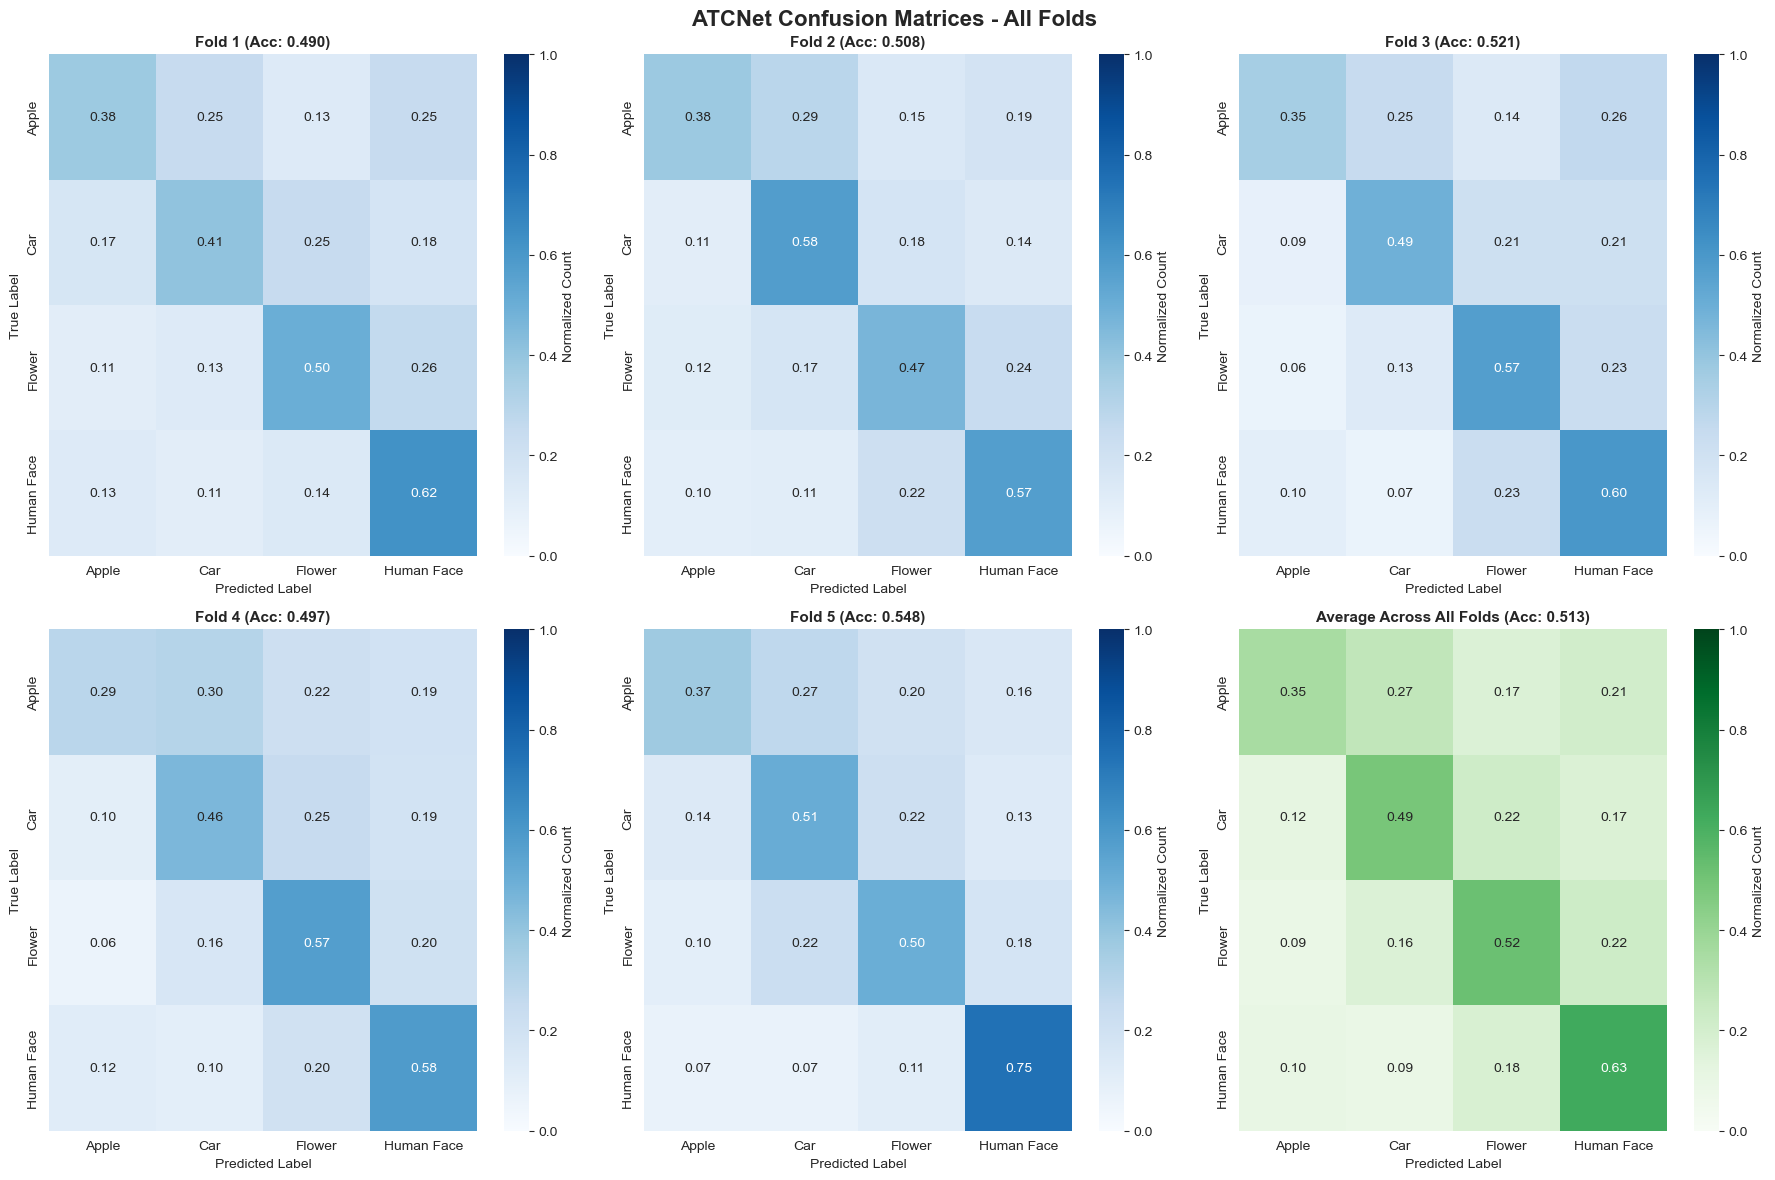

✅ Confusion matrices plot saved to: atcnet_confusion_matrices.png
✅ Confusion matrix data saved to: atcnet_confusion_matrix.csv


In [9]:
# Plot confusion matrices for all folds
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('ATCNet Confusion Matrices - All Folds', fontsize=16, fontweight='bold')

for fold_idx, cm in enumerate(all_confusion_matrices):
    row = fold_idx // 3
    col = fold_idx % 3
    
    # Normalize confusion matrix
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Plot
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[row, col], cbar_kws={'label': 'Normalized Count'},
                vmin=0, vmax=1)
    
    axes[row, col].set_title(f'Fold {fold_idx + 1} (Acc: {results_df.iloc[fold_idx]["Accuracy"]:.3f})',
                             fontsize=11, fontweight='bold')
    axes[row, col].set_xlabel('Predicted Label', fontsize=10)
    axes[row, col].set_ylabel('True Label', fontsize=10)

# Calculate and plot average confusion matrix
avg_cm = np.mean(all_confusion_matrices, axis=0)
avg_cm_normalized = avg_cm / avg_cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(avg_cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1, 2], cbar_kws={'label': 'Normalized Count'},
            vmin=0, vmax=1)

axes[1, 2].set_title(f'Average Across All Folds (Acc: {summary_df[summary_df["Metric"]=="Accuracy"]["Mean"].values[0]:.3f})',
                     fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel('Predicted Label', fontsize=10)
axes[1, 2].set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.savefig('atcnet_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Confusion matrices plot saved to: atcnet_confusion_matrices.png")

# Save confusion matrix data
cm_data = []
for fold_idx, cm in enumerate(all_confusion_matrices):
    for i, true_class in enumerate(class_names):
        for j, pred_class in enumerate(class_names):
            cm_data.append({
                'Fold': fold_idx + 1,
                'True_Class': true_class,
                'Predicted_Class': pred_class,
                'Count': cm[i, j]
            })

cm_df = pd.DataFrame(cm_data)
cm_df.to_csv('atcnet_confusion_matrix.csv', index=False)
print("✅ Confusion matrix data saved to: atcnet_confusion_matrix.csv")

In [10]:
print("\n" + "="*80)
print("ATCNet TRAINING COMPLETED - FINAL SUMMARY")
print("="*80)
print(f"\nModel: ATCNet (Attention-based Temporal Convolutional Network)")
print(f"Architecture Components:")
print(f"  - Convolutional Blocks (EEGNet-inspired spatial-temporal filtering)")
print(f"  - Multi-head Self-Attention ({MODEL_PARAMS['attention_heads']} heads)")
print(f"  - Temporal Convolutional Network ({MODEL_PARAMS['tcn_depth']} layers)")
print(f"  - Attention-based Pooling")
print(f"\nModel Parameters: {sum(p.numel() for p in ATCNet(**MODEL_PARAMS).parameters()):,}")
print(f"\nDataset:")
print(f"  - Total Samples: 3612")
print(f"  - Classes: 4 (Apple, Car, Flower, Human Face)")
print(f"  - Input Shape: (1, 14, 128) - [Channels, EEG Channels, Time Points]")
print(f"  - Features: 14 channels × 128 time points = 1792")
print(f"\nTraining Configuration:")
print(f"  - Cross-Validation: 5-Fold Stratified")
print(f"  - Batch Size: {BATCH_SIZE}")
print(f"  - Learning Rate: {LEARNING_RATE}")
print(f"  - Optimizer: Adam")
print(f"  - Loss Function: CrossEntropyLoss")
print(f"  - Early Stopping Patience: {PATIENCE}")
print(f"  - LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)")
print(f"  - Device: {device}")
print(f"\n" + "-"*80)
print("PERFORMANCE METRICS (Mean ± Std):")
print("-"*80)
for _, row in summary_df.iterrows():
    print(f"{row['Metric']:20s}: {row['Mean']:.4f} ± {row['Std']:.4f}")

print("\n" + "-"*80)
print("PER-FOLD ACCURACY:")
print("-"*80)
for _, row in results_df.iterrows():
    print(f"Fold {int(row['Fold'])}: {row['Accuracy']:.4f} (Best Epoch: {int(row['Best_Epoch'])})")

print("\n" + "="*80)
print("OUTPUT FILES GENERATED:")
print("="*80)
print("  ✅ atcnet_results_summary.csv        - Summary statistics")
print("  ✅ atcnet_fold_details.csv           - Detailed per-fold results")
print("  ✅ atcnet_confusion_matrix.csv       - Confusion matrix data")
print("  ✅ atcnet_training_history.png       - Training history visualization")
print("  ✅ atcnet_confusion_matrices.png     - Confusion matrices visualization")
print("="*80)

print("\n🎉 ATCNet training pipeline completed successfully!")
print("="*80)


ATCNet TRAINING COMPLETED - FINAL SUMMARY

Model: ATCNet (Attention-based Temporal Convolutional Network)
Architecture Components:
  - Convolutional Blocks (EEGNet-inspired spatial-temporal filtering)
  - Multi-head Self-Attention (2 heads)
  - Temporal Convolutional Network (2 layers)
  - Attention-based Pooling

Model Parameters: 39,109

Dataset:
  - Total Samples: 3612
  - Classes: 4 (Apple, Car, Flower, Human Face)
  - Input Shape: (1, 14, 128) - [Channels, EEG Channels, Time Points]
  - Features: 14 channels × 128 time points = 1792

Training Configuration:
  - Cross-Validation: 5-Fold Stratified
  - Batch Size: 32
  - Learning Rate: 0.001
  - Optimizer: Adam
  - Loss Function: CrossEntropyLoss
  - Early Stopping Patience: 15
  - LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)
  - Device: cuda

--------------------------------------------------------------------------------
PERFORMANCE METRICS (Mean ± Std):
----------------------------------------------------------------

## 10. Final Summary and Model Comparison

## 9. Visualize Confusion Matrices

## 8. Visualize Training History

## 7. Aggregate Results and Performance Summary

## 6. 5-Fold Cross-Validation Training

## 5. Training and Evaluation Functions

## 4. Load and Prepare Data from Cross-Validation Folds